# 03 Pretrained ResNet-50 features

**Owner:** Fatema. **Runs in:** about 11 minutes on 4 CPU cores (no GPU needed).

- ResNet-50 with the original ImageNet weights (torchvision `IMAGENET1K_V1`, He et al. 2016). **No training or fine-tuning.**
- The final classification layer is replaced with "do nothing", so the output is the 2,048 values from global average pooling: a summary of which visual patterns (petal shapes, centres, textures, parts) appear in the image.
- Input: the same 224x224 crop as the hand-crafted features, normalised with the ImageNet mean and standard deviation.
- Each 2,048-value vector is scaled to unit length (L2), so distances depend on *what* is in the image, not how strongly.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from p22 import config, data
pd.set_option("display.precision", 3)
import torch
from p22 import cnn

## 1. The model

In [2]:
model = cnn.build_model()
print(model.fc)  # Identity: the 1,000-class ImageNet head is gone
print(sum(p.numel() for p in model.parameters()) / 1e6, "million weights, all frozen")

Identity()
23.508032 million weights, all frozen


## 2. One image through the network

In [3]:
with torch.no_grad():
    v = model(cnn.to_tensor(data.load_image(data.image_paths()[0]))[None])[0].numpy()
print(v.shape, f"min {v.min():.2f}, max {v.max():.2f}, share of zeros {np.mean(v == 0):.2f}")

(2048,) min 0.00, max 4.36, share of zeros 0.00


## 3. All images
Cached by `scripts/extract_features.py`; set `RECOMPUTE = True` to run it again here.

In [4]:
RECOMPUTE = False
X = cnn.extract(data.image_paths()) if RECOMPUTE else np.load(config.FEATURES_DIR / "resnet50.npy")
print(X.shape)
print(json.dumps(json.loads((config.RESULTS_DIR / "features_log.json").read_text()), indent=1)[:400])

(8189, 2048)
{
 "hardware": {
  "cpu": "x86_64",
  "threads": 4,
  "gpu": false
 },
 "torch": "2.14.1+cpu",
 "handcrafted_seconds": 102.0,
 "resnet50_seconds": 648.6,
 "feature_sha256": {
  "hsv_hist": "403d0f9784b1559261a9d4acaa6d462986e4d2d00cffc6dca7e87c2f64de3c02",
  "lbp": "ac94b2f93103159b8de0493714185b7afec75d1298e0ab8a64917554fded3754",
  "mean_rgb": "6950bfbc01a4440a3b912373b9c9327259f72bf3609040fc935


## 4. Do nearby vectors look alike? (no labels used)
For a few query images, the 5 nearest images by cosine similarity, inside the selection set only. If the features are useful for clustering, the neighbours should look like the same kind of flower.

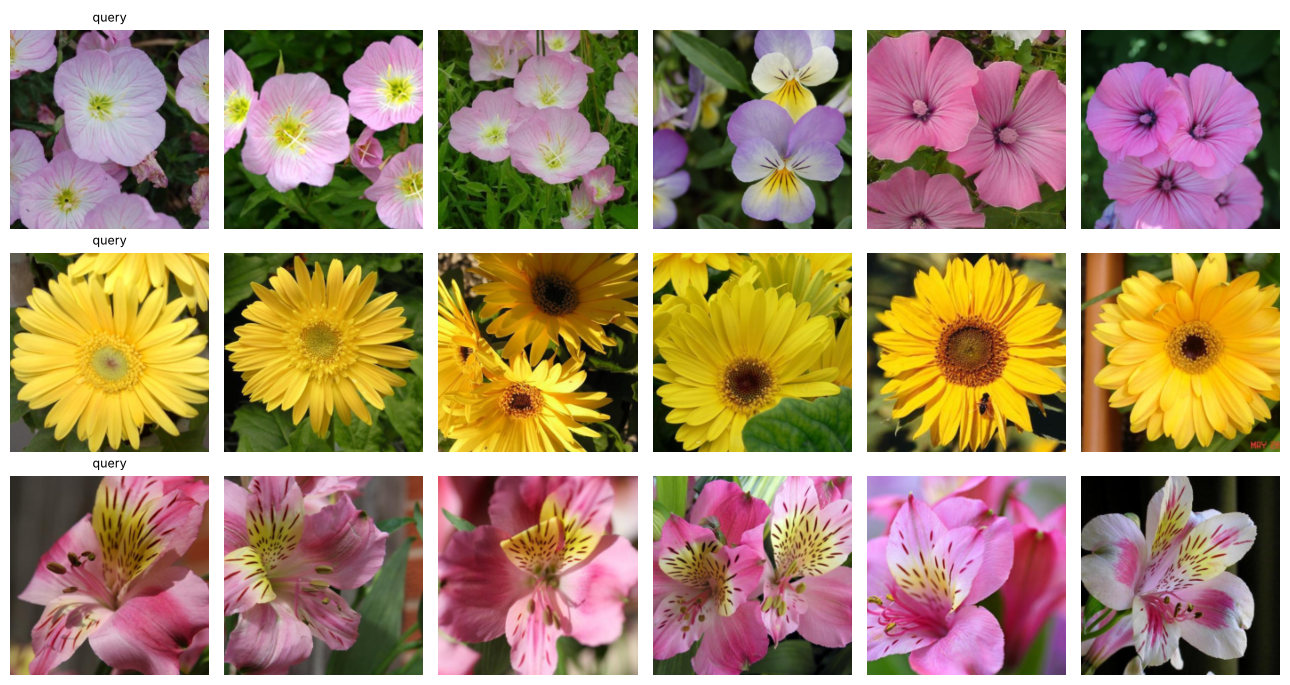

In [5]:
from sklearn.preprocessing import normalize
split = data.load_split()
sel = split["selection"]
Z = normalize(X[sel])
paths = data.image_paths()
queries = [0, 400, 1200]
fig, axes = plt.subplots(len(queries), 6, figsize=(13, 2.3 * len(queries)))
for row, q in zip(axes, queries):
    nearest = np.argsort(-Z @ Z[q])[:6]
    for ax, j in zip(row, nearest):
        ax.imshow(data.load_image(paths[sel[j]])); ax.axis("off")
    row[0].set_title("query", fontsize=9)
plt.tight_layout()